<a href="https://colab.research.google.com/github/Rogerkamana/Assignment4_rk/blob/main/Lesson_6_ml_basic_assignmentRk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Assignment Simple machine Learning Project cycle**
## **_Assignment 6: House Price Prediction Using California Housing Data_**
This dataset provides information about house prices in California. House Price Prediction

In this notebook, you'll follow the basic machine learning process to build a regression model to predict house prices using the "California Housing Dataset" from sklearn.

Follow the instructions and complete each TODO to complete the assessment on the essential steps in building and evaluating a regression model.
The following is a description of each column in the dataset:

Dataset Features (California Housing):

MedInc: Median income in block group
HouseAge: Median house age in block group
AveRooms: Average number of rooms per household
AveBedrms: Average number of bedrooms per household
Population: Block group population
AveOccup: Average number of household members
Latitude: Block group latitude
Longitude: Block group longitude
MedHouseVal (Target): Median house value in block group

Lonk to colab:https://colab.research.google.com/drive/1MljhhypV8MgAJ2_vjEKPj4fR-cTOY6L8

Link to GitHub:https://github.com/Rogerkamana/Assignment4_rk/blob/18ba885b5d7ba096702335d356f7b39b1d05ab5f/Lesson_6_ml_basic_assignmentRk.ipynb

## 1. Imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

## 2. Data Collection and Loading

In [ ]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()
features = housing.feature_names
target = "MedHouseVal"
print(f"Rows: {len(df):,} | Predictors: {len(features)}")

Rows: 20,640 | Predictors: 8


## 3. Quick Check of Data

In [ ]:
print(df.head().round(3).to_string())
print()
df.info()
print()
print(df.describe().T.round(3).to_string())
print()
print("MedHouseVal is a continuous target measured in $100,000 units.")
print("Population is a discrete count. HouseAge is recorded in whole years.")
print("The other predictors are continuous numeric measurements.")
print("There are no categorical features.")

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  Longitude  MedHouseVal
0   8.325      41.0     6.984      1.024       322.0     2.556     37.88    -122.23        4.526
1   8.301      21.0     6.238      0.972      2401.0     2.110     37.86    -122.22        3.585
2   7.257      52.0     8.288      1.073       496.0     2.802     37.85    -122.24        3.521
3   5.643      52.0     5.817      1.073       558.0     2.548     37.85    -122.25        3.413
4   3.846      52.0     6.282      1.081       565.0     2.181     37.85    -122.25        3.422

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup  

## 4. EDA and Data Preprocessing

### Check for missing values

In [ ]:
missing = df.isna().sum()
print(missing.to_string())
print(f"Total missing values: {missing.sum()}")
print("No imputation is needed.")

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
Total missing values: 0
No imputation is needed.


### Plot median income against median house value

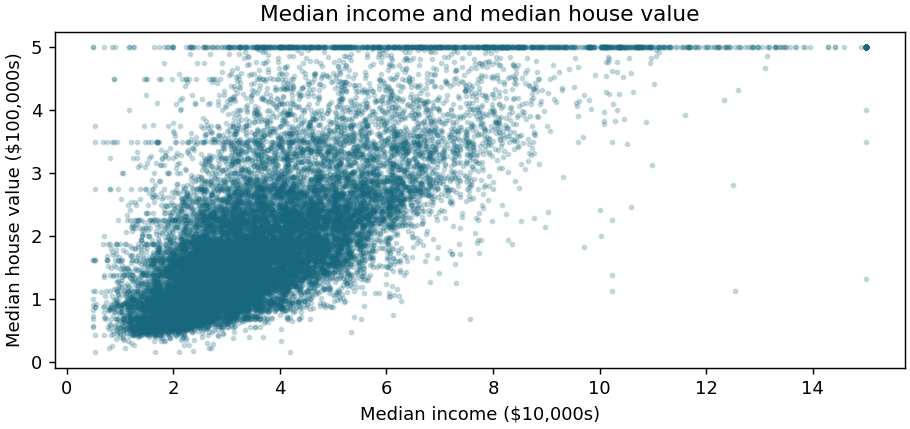

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.3), layout="constrained")
ax.scatter(df["MedInc"], df[target], s=5, alpha=0.2, color="#17677e")
ax.set(
    title="Median income and median house value",
    xlabel="Median income ($10,000s)",
    ylabel="Median house value ($100,000s)",
)
plt.show()

### Define the reusable scatter plot function

In [ ]:
def plot_feature_scatter(data, feature_names, target_name):
    nrows = (len(feature_names) + 1) // 2
    fig, axes = plt.subplots(
        nrows, 2, figsize=(9, 2.05 * nrows), sharey=True,
        squeeze=False, layout="constrained",
    )
    for ax, feature in zip(axes.flat, feature_names):
        ax.scatter(data[feature], data[target_name], s=4,
                   alpha=0.2, color="#17677e")
        ax.set(xlabel=feature, ylabel="Value ($100,000s)")
    for ax in axes.flat[len(feature_names):]:
        ax.set_visible(False)
    fig.suptitle(f"Predictor relationships with {target_name}")
    plt.show()

### Visualize all eight predictors

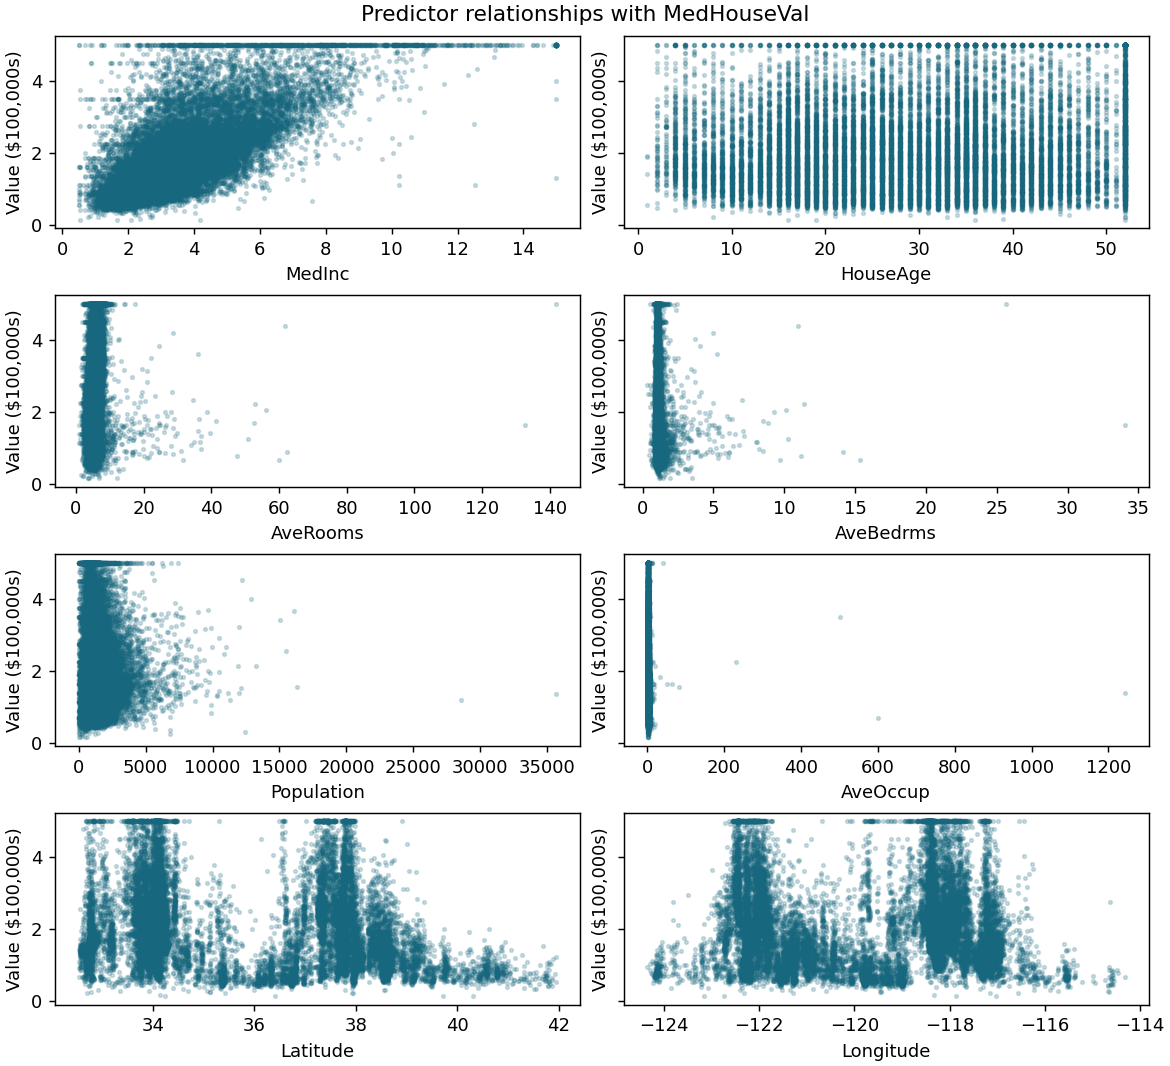

In [ ]:
plot_feature_scatter(df, features, target)

Median income generally rises with median house value. The horizontal band near $500,000 reflects the dataset’s upper value cap. Large values for average rooms and occupancy stretch their plot axes.

## 5. ML Model Training

In [ ]:
X = df[features]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)
print(f"Training observations: {len(X_train):,}")
print(f"Test observations: {len(X_test):,}")

Training observations: 16,512
Test observations: 4,128


## 6. Model Evaluation

In [ ]:
y_pred = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print(f"RMSE: {rmse:.4f} in $100,000 units (USD {rmse * 100_000:,.0f})")
print(f"R-squared: {r2:.4f}")
print(f"The model explains {r2:.1%} of the variation in the test set.")

RMSE: 0.7456 in $100,000 units (USD 74,558)
R-squared: 0.5758
The model explains 57.6% of the variation in the test set.


## 7. Model Prediction

In [ ]:
new_block_group = pd.DataFrame([{
    "MedInc": 3.0,
    "HouseAge": 30.0,
    "AveRooms": 6.0,
    "AveBedrms": 1.0,
    "Population": 1500.0,
    "AveOccup": 3.0,
    "Latitude": 34.0,
    "Longitude": -118.0,
}], columns=features)

prediction = model.predict(new_block_group)[0]
print(f"Predicted median house value: USD {prediction * 100_000:,.2f}")

Predicted median house value: USD 154,866.33
